**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_044_초급_회귀_공공자전거수요예측

### **대여소 데이터를 활용한 <span style="color:darkgreen">시간당 반납 건수</span> 예측**
---

- 도메인 : 공공자전거 수요 예측
- 목  표 : 대여소의 시간당 반납 건수를 예측하는 인공지능모델 개발
- 최근 대여소 관련 현안이 늘면서 여문모빌리티는 데이터 기반의 판단 체계가 필요하다고 보고 있다.
- 여문모빌리티의 데이터팀은 축적된 대여소 데이터를 활용해 대여소의 시간당 반납 건수를 예측하는 모델을 만들어 보기로 했다.
- 제공되는 데이터는 대여소 단위로 정리된 약 710건의 기록이다.
- 모델이 시간당 반납 건수를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 여문모빌리티의 데이터로 대여소의 시간당 반납 건수를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, select_dtypes, columns, corr, quantile, reset_index, drop, dropna, sum, isnull, get_dummies, info, DataFrame, sort_values, shape) · NumPy(sqrt) · seaborn(heatmap) · matplotlib(show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, StandardScaler, fit_transform, transform, LinearRegression, fit, RandomForestRegressor, feature_importances_, predict, mean_squared_error) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, BatchNormalization, Dropout, history)
- 난이도 : 초급 (설계 난이도 점수 2.69 / 5)
- 예상 소요 시간 : 약 116분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 공공자전거 수요 예측 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- uid                   : 고유 식별번호
- tempC                 : 기온(℃)
- humidity              : 습도(%)
- windMs                : 풍속(m/s)
- rainfallMm            : 강수량(mm)
- hour                  : 시각(시)
- dustPm10              : 미세먼지(㎍/㎥)
- visibilityM           : 가시거리(m)
- dockCnt               : 거치대 수
- stationPop            : 반경 500m 거주 인구(천명)
- prevHourRent          : 직전 시간 대여 수
- season                : 계절
- holiday               : 휴일 여부
- district              : 구역
- weather               : 날씨
- returnCnt             : 시간당 반납 건수

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `pandas`
- as 뒤에 쓸 이름(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [ ]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pd'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 2글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as p_

정답01 = 'p_'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 아래 안내대로 파일을 읽어 df_raw 에 저장하고 처음 6개 행을 확인하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 저장할 변수 이름 : df_raw
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽어 올 파일 : data.csv
- **[정답02]** 읽어 온 데이터의 **행(row)의 개수** 를 작성하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [3]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

df_raw = pd.read_csv('./data.csv')
df_raw.head(6)

print(df_raw.shape[0])


708


In [ ]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = '708'

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df_raw 로 행(row)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(6)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df_raw.shape[__])
```

</details>

### **3. 데이터의 컬럼들 중 자료형이 같은 것만 골라 따로 다루려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(select_dtypes, columns) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- df_raw 에서 **수치형이 **아닌**(문자열 등)** 컬럼만 `select_dtypes` 로 선택해 `selected` 에 보관하세요
    - 선택된 컬럼 이름 목록을 `tolist()` 로 만들어 `selected_cols` 에 담으세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [4]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

selected = df_raw.select_dtypes(exclude='number')
selected_cols = selected.columns.tolist()

In [ ]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'select_dtypes'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

자료형을 기준으로 컬럼을 고르는 DataFrame 메서드와 include/exclude 옵션을 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `select_dtypes`, `tolist`. 정답은 13글자이고 첫 글자는 `s` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
selected = df_raw.select_______(exclude='number')
selected_cols = selected.columns.tolist()

정답03 = 'select_______'   # 빈칸에 넣은 단어
```

</details>

### **4. 선택한 수치형 변수들의 상관관계를 히트맵으로 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: pandas(corr) · seaborn(heatmap) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 대상 변수 : hour, dustPm10, visibilityM, tempC, rainfallMm
- 상관계수 행렬을 구한 뒤 seaborn heatmap 으로 시각화하세요
- 상관계수 값을 표시(annot=True)하고, 색상 팔레트(cmap)는 'viridis' 로 지정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

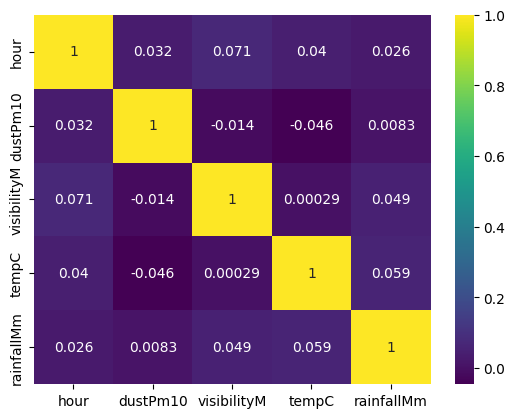

In [5]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.heatmap(df_raw[['hour', 'dustPm10', 'visibilityM', 'tempC', 'rainfallMm']].corr(), annot=True, cmap='viridis')
plt.show()

In [ ]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'corr'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

상관계수 행렬을 색으로 표현하는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `.corr()`, `sns.heatmap`. 정답은 4글자이고 첫 글자는 `c` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df_raw[['hour', 'dustPm10', 'visibilityM', 'tempC', 'rainfallMm']].co__(), annot=True, cmap='viridis')
plt.show()

정답04 = 'co__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 강수량(mm)(rainfallMm) 컬럼의 이상치를 IQR 기준으로 제거할 계획입니다. 아래 안내대로 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 사분위수(Q1, Q3)와 IQR 을 구하세요
- lower_fence = Q1 - 1.5 x IQR, upper_fence = Q3 + 1.5 x IQR 로 정의하세요
- rainfallMm 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 uid 도 삭제하고 인덱스를 0부터 다시 매겨 df_clean 에 저장하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [6]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = df_raw['rainfallMm'].quantile(0.25)
q3 = df_raw['rainfallMm'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['rainfallMm'] > upper_fence) | (df_raw['rainfallMm'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['uid']).reset_index(drop=True)

In [ ]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df_raw['rainfallMm'].quan____(0.25)
q3 = df_raw['rainfallMm'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['rainfallMm'] > upper_fence) | (df_raw['rainfallMm'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['uid']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 아래 안내대로 결측치를 처리하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 대상 데이터프레임 : df_clean
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 df_filled 에 저장하세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답06]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [7]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

print( '결측치 처리 전\n', df_clean.isnull().sum() )
df_filled = df_clean.dropna()
print( '결측치 처리 후\n', df_filled.isnull().sum() )

결측치 처리 전
 tempC            0
humidity        66
windMs           0
rainfallMm       0
hour             0
dustPm10         0
visibilityM      0
dockCnt          0
stationPop       0
prevHourRent     0
season           0
holiday          0
district         0
weather          0
returnCnt        0
dtype: int64
결측치 처리 후
 tempC           0
humidity        0
windMs          0
rainfallMm      0
hour            0
dustPm10        0
visibilityM     0
dockCnt         0
stationPop      0
prevHourRent    0
season          0
holiday         0
district        0
weather         0
returnCnt       0
dtype: int64


In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 'isnull'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치 여부를 True/False 로 돌려주는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `i` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', df_clean.isn___().sum() )
df_filled = df_clean.dropna()
print( '결측치 처리 후\n', df_filled.isnull().sum() )

정답06 = 'isn___'   # 빈칸에 넣은 단어
```

</details>

### **7. 원-핫 인코딩은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 변환하는 코드를 수정하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(get_dummies, info) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 제시된 가이드에 맞춰 인코딩하는데 실행 중 예외가 발생합니다. 코드의 오류를 정정하세요
    - 대상 데이터프레임 : df_filled
    - 문자열(범주형) 컬럼 season, holiday, district, weather 을(를) get_dummies 로 인코딩하세요 (타깃 returnCnt 은 제외, drop_first=True)
    - 인코딩된 데이터프레임은 df_final 에 저장하고 info() 로 구조를 확인하세요
- **[정답07]** 인코딩 후 df_final 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [8]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_final = pd.get_dummies(data=df_filled, columns=['season', 'holiday', 'district', 'weather'], drop_first=True)
df_final.info()

df_final.shape[1]

<class 'pandas.core.frame.DataFrame'>
Index: 575 entries, 0 to 640
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   tempC         575 non-null    float64
 1   humidity      575 non-null    float64
 2   windMs        575 non-null    float64
 3   rainfallMm    575 non-null    float64
 4   hour          575 non-null    float64
 5   dustPm10      575 non-null    float64
 6   visibilityM   575 non-null    float64
 7   dockCnt       575 non-null    float64
 8   stationPop    575 non-null    float64
 9   prevHourRent  575 non-null    float64
 10  returnCnt     575 non-null    float64
 11  season_겨울     575 non-null    bool   
 12  season_봄      575 non-null    bool   
 13  season_여름     575 non-null    bool   
 14  holiday_휴일    575 non-null    bool   
 15  district_대학   575 non-null    bool   
 16  district_도심   575 non-null    bool   
 17  district_주거   575 non-null    bool   
 18  weather_비     575 non-null    bool 

20

In [ ]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = '20'

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

get_dummies 호출의 인자 이름을 점검하세요. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_final = pd.get_dummies(data=df_filled, columns=['season', 'holiday', 'district', 'weather'], drop_first=True)
df_final.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_final.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 검증 레이블의 분포를 확인하고자 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 시간당 반납 건수(returnCnt) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 지정하세요
- 데이터를 훈련 70 : 검증 30 로 분할합니다 (test_size=0.3)
- 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
- 결과를 재현할 수 있게 random_state 값을 100 로 지정하세요
- 분리에는 sklearn.model_selection 의 train_test_split 을 사용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [11]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_final.drop('returnCnt', axis=1)
y = df_final['returnCnt']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=100)

In [ ]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'test_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 9글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('returnCnt', axis=1)
y = df_final['returnCnt']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_____=0.3, random_state=100)

정답08 = 'test_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 가이드에 따라 스케일링 처리하는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 sc 변수에 설정하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수점 둘째 자리까지 작성하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [12]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

round(np.min(X_valid), 2)


np.float64(-2.9)

In [ ]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = '-2.9'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10번. [AI 모델링] 시간당 반납 건수(returnCnt)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=50, max_depth=6
    - 난수 시드(random_state) : 7
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수점 둘째 자리까지 입력하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [17]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=7)
rf.fit(X_train, y_train)

round(lin.intercept_, 2)


np.float64(246.83)

In [ ]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = '246.83'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `RandomForestRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=50, max_depth=6, random_state=7)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. RandomForest 모델의 변수중요도 상위 3개 변수가 전체 설명력의 얼마를 차지하는지 확인하고자 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, reset_index, head, columns) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `rf`
- 학습된 RandomForest 모델 `rf` 의 변수중요도를 변수명과 매핑한 DataFrame `fi` 로 만들고 내림차순 정렬하세요
    - 상위 3개 행을 `top_n` 에 담으세요
- **[정답11]** 상위 3개 변수 중요도의 **합계**를 소수 둘째 자리까지 기입하세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [18]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

round(top_n['importance'].sum(), 2)


np.float64(0.77)

In [ ]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = '0.77'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

중요도 DataFrame 을 만들어 정렬한 뒤 위에서 N개를 선택합니다. top_n 의 importance 컬럼을 합하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `feature_importances_`, `sort_values`, `head`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False).reset_index(drop=True)
top_n = fi.head(3)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(top_n['____'].sum(), __)
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: NumPy(sqrt) · scikit-learn(predict, mean_squared_error) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `lin`, `rf`
- 아래 가이드에 따라 각 모델의 RMSE(제곱근평균제곱오차) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 lin 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 RMSE(제곱근평균제곱오차) 값을 각각 linreg_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 RMSE(제곱근평균제곱오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [20]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = np.sqrt(mean_squared_error(y_valid, y_pred_linreg))
rf_score = np.sqrt(mean_squared_error(y_valid, y_pred_rf))
print(linreg_score, rf_score)

59.84918450848372 55.40569010691066


In [ ]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

RMSE(제곱근평균제곱오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.metrics import mean_squared_error

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = np.sqrt(mean_squared_error(y_valid, y_pred_linreg))
rf_score = np.sqrt(mean_squared_error(y_valid, y_pred_rf))
print(linreg_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 시간당 반납 건수(returnCnt)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- tensorflow framework 를 사용하세요
- Dense 은닉층 2개를 노드 수 [16, 8] 순서로 쌓고, 활성화 함수는 'elu' 를 쓰세요
- EarlyStopping 으로 10번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 저장하세요
- 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
- 첫 번째 은닉층 뒤에 Dropout(0.2) 층을 두세요
- 출력층은 노드 1개, activation='linear' 로 하세요
- 모델을 컴파일할 때 optimizer 는 adam, 손실 함수는 mse, 평가지표는 [mae] 로 하세요
- batch_size 는 32, epochs 는 30 로 학습하고 학습정보는 history 변수에 보관하세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
- 안내된 내용 외 별도의 파라미터를 입력하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [22]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(16, activation='elu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.2),
    Dense(8, activation='elu'),
    BatchNormalization(),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'Dropout'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 학습 중 일부 뉴런을 무작위로 꺼서 과적합을 줄이는 층입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 7글자이고 첫 글자는 `D` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(16, activation='elu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Drop___(0.2),
    Dense(8, activation='elu'),
    BatchNormalization(),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=32,
                    validation_data=(X_valid, y_valid),
                    verbose=0,
                    callbacks=cb_list)

정답13 = 'Drop___'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 MAE와(과) 검증 MAE의 변화를 그래프로 시각화하십시오.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 MAE 과 검증 MAE 2가지를 모두 표시하세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model MAE' 로, X축 이름은 'Epochs', Y축 이름은 'MAE' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

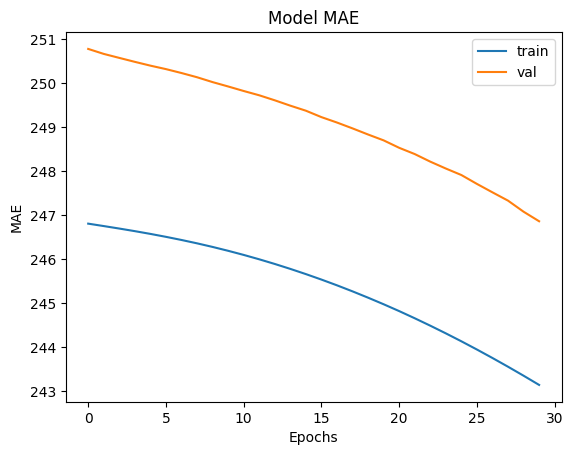

In [23]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'title'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 그래프 제목을 지정하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 5글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.tit__('Model MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend(['train', 'val'])
plt.show()

정답14 = 'tit__'   # 빈칸에 넣은 단어
```

</details>